In [2]:
import pandas as pd
import numpy as np
import torch
import tqdm

import matplotlib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_percentage_error, 
    root_mean_squared_error
)

In [3]:
import dataset as ds
import models as ml
import helper as hl
import train as tr

In [4]:
N_BANDS = 18

# Load ITC Dataset

In [5]:
patches_dataset_clean = pd.read_pickle(
    './data/pkl/'+\
    f'Targeted fertilization v3.patches_dataset.kernel=8_stride=1_bands={N_BANDS}.weather.land=Wheat_ph=2.v3.pkl'
)

In [6]:
_, _, gerk_test = pd.read_pickle(f'./data/pkl/Targeted fertilization v3.patches_dataset.kernel=8_stride=1_bands={N_BANDS}.weather.land=Wheat_ph=2.v3.train-dev-test-splits.pkl')

In [7]:
patches_dataset_test = patches_dataset_clean.loc[
    pd.IndexSlice[gerk_test, :, :]
].copy()

# Load Model

In [8]:
model_path = './data/pth/'+\
f'UNet_in-channels={N_BANDS}_hidden-channels=24_36_48_out-channels=1_patches-kernel=8_stride=1_batch-size=64_ITC-sample-data_dropout_p=0_25_patience=10_aug_land=Wheat_ph=2/'+\
f'UNet_in-channels={N_BANDS}_hidden-channels=24_36_48_out-channels=1_patches-kernel=8_stride=1_batch-size=64_ITC-sample-data_dropout_p=0_25_patience=10_aug_land=Wheat_ph=2.v12.epoch{{0}}.pth'
# model_path = './data/pth/'+\
# f'UNet_in-channels={N_BANDS}_hidden-channels=4_8_16_out-channels=1_patches-kernel=8_stride=1_batch-size=64_ITC-sample-data_dropout_p=0_25_patience=10_aug_land=Wheat_ph=2/'+\
# f'UNet_in-channels={N_BANDS}_hidden-channels=4_8_16_out-channels=1_patches-kernel=8_stride=1_batch-size=64_ITC-sample-data_dropout_p=0_25_patience=10_aug_land=Wheat_ph=2.v12.epoch{0}.pth'
# model_path = './data/pth/'+\
# f'UNet_in-channels={N_BANDS}_hidden-channels=72_84_96_out-channels=1_patches-kernel=8_stride=1_batch-size=64_ITC-sample-data_dropout_p=0_25_patience=10_aug_land=Wheat_ph=2/'+\
# f'UNet_in-channels={N_BANDS}_hidden-channels=72_84_96_out-channels=1_patches-kernel=8_stride=1_batch-size=64_ITC-sample-data_dropout_p=0_25_patience=10_aug_land=Wheat_ph=2.v12.epoch{0}.pth'

In [9]:
model = ml.UNet(
    N_BANDS, 1, [24,36,48], dropout=0.25
    # N_BANDS, 1, [4,8,16], dropout=0.25
    # N_BANDS, 1, [72,84,96], dropout=0.25
)

In [10]:
model_dict = torch.load(model_path.format('best'), map_location=torch.device('cpu'))

In [11]:
model.load_state_dict(model_dict['model_state_dict'])

<All keys matched successfully>

# Evaluate model on the test set of ITC dataset

In [12]:
patches_dataset_test_th = ds.ITC_Patches(
    [arr.squeeze(0) for arr in patches_dataset_test.input_patches.values.tolist()], 
    [arr.squeeze(0) for arr in patches_dataset_test.output_patches.values.tolist()], 
    transform = model_dict['transform']
)

patches_dataset_test_th_loader = torch.utils.data.DataLoader(patches_dataset_test_th, batch_size:=32, shuffle=False)

In [13]:
criterion = tr.RMSELoss_masked(ignore_index=torch.tensor([NO_DATA_VALUE := -9999]).float())
device = torch.device('cpu')

test_loss = tr.model_dev_loss(model, device=device, criterion=criterion, dev_loader=patches_dataset_test_th_loader, criterion_fun=tr.calc_loss, criterion_fun_params={})
print(f'Best Model | Test Loss: {test_loss}')

self.eps=0.001


Best Model | Test Loss: 12.32123851776123


### Evaluate TerrAI at the patch level

In [14]:
no_data = torch.tensor([NO_DATA_VALUE]).float()

results_dict = {
    'smape': [],
    'mape': [],
    'rmse': [],
}

model.eval()
with torch.no_grad():
    dev_loss = []
    for (xb, yb, *args) in (pbar := tqdm.tqdm(patches_dataset_test_th_loader, leave=False, total=len(patches_dataset_test_th_loader), dynamic_ncols=True)):
        if xb.shape[0] == 1:
            continue

        xb = xb.to(device).float()
        yb = yb.to(device).float()
        args = (arg.to(device) for arg in args)

        if isinstance(criterion, torch.nn.CrossEntropyLoss):
            yb = yb.to(device).squeeze(1).long()

        mask = ~torch.isclose(yb, no_data)
        y_pred = model(xb, *args)
        
        for i in range(yb.shape[0]):
            # Avoid comparing patches with no data (less than two samples)
            if np.count_nonzero(mask[i]) < 2:
                continue

            results_dict['mape'].append(
                mean_absolute_percentage_error(
                    yb[i][mask[i]].numpy(), 
                    y_pred[i][mask[i]].numpy()
                )
            )
            results_dict['smape'].append(
                tr.smape(
                    yb[i][mask[i]].numpy(), 
                    y_pred[i][mask[i]].numpy()
                )
            )
            results_dict['rmse'].append(
                root_mean_squared_error(
                    yb[i][mask[i]].numpy(), 
                    y_pred[i][mask[i]].numpy()
                )
            )

np.mean(results_dict['rmse']),\
np.mean(results_dict['mape'])*100,\
np.mean(results_dict['smape'])

(12.305583, 5.307424813508987, 5.230373151262682)

### Evaluate TerrAI at the prescription map level

0.056664374	5.797995240375445	13.751814
0.036050618	3.781017393577756	13.520652
0.042431593	4.203729484776824	10.9741535
0.26748243	23.213971829881853	43.888577
0.083604045	8.817719552491116	24.16943


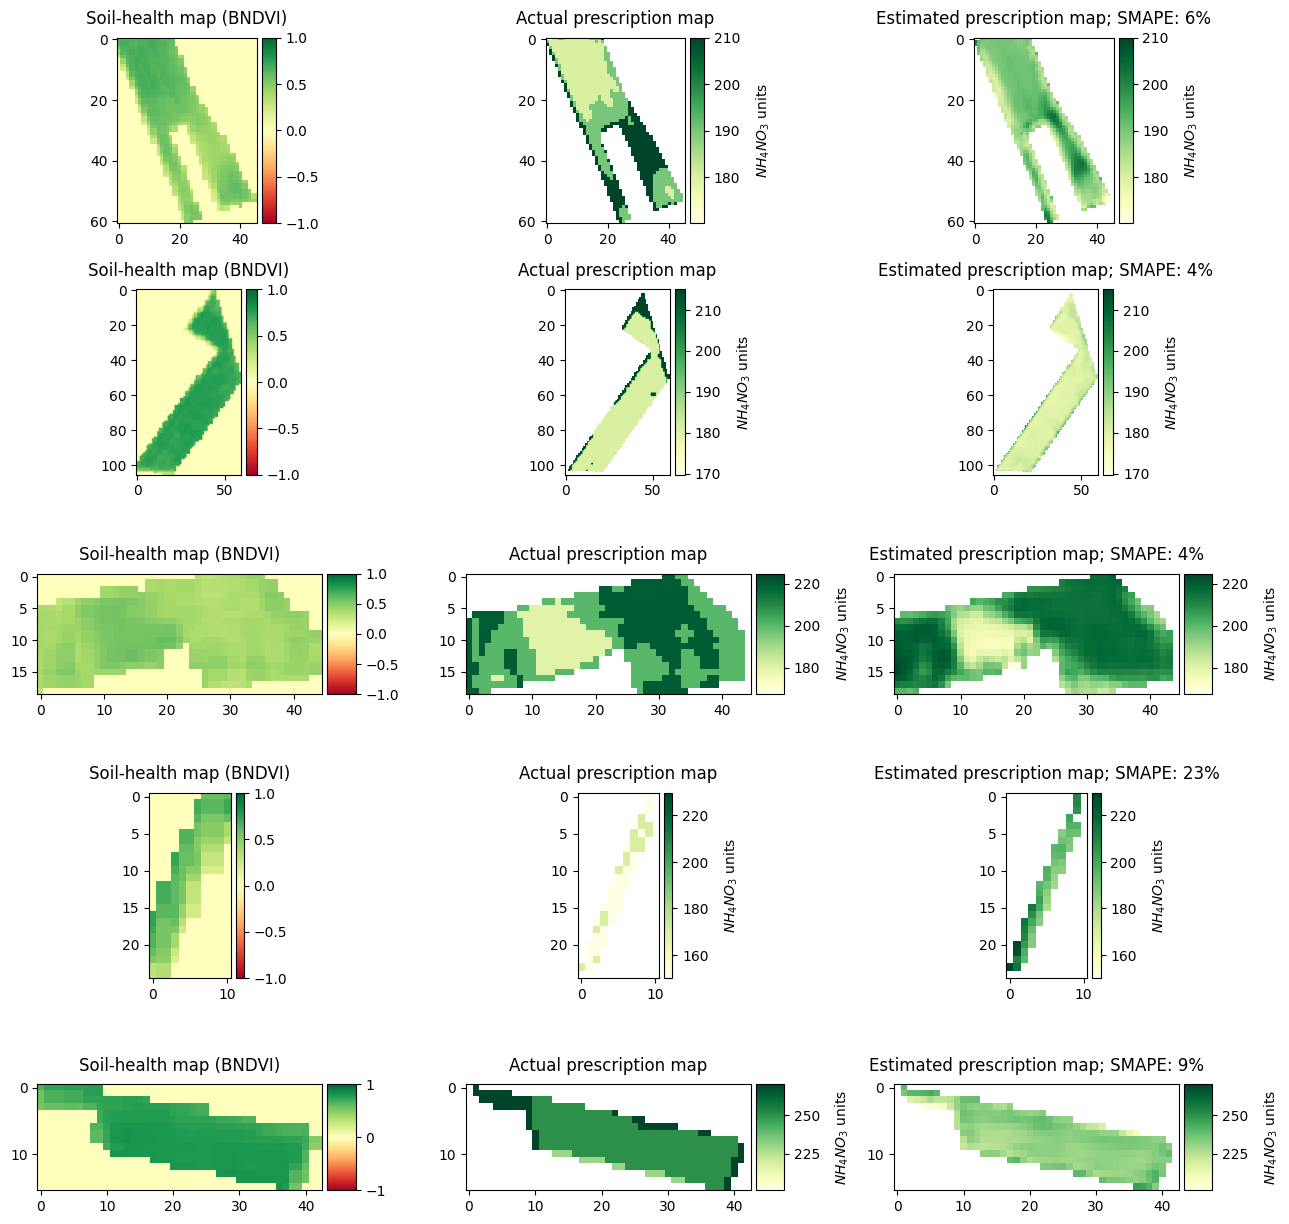

In [15]:
fig, ax = plt.subplots(len(patches_dataset_test), 3, figsize=(13, 2.5 * len(patches_dataset_test)))
cmap = matplotlib.cm.RdYlGn
cmap.set_bad(color='black')

for axes, raster_data in zip(ax, patches_dataset_test.itertuples()):
    model_pred = hl.model_inference(
        model, raster_data, model_dict['transform'], 8, 1, device=device
    )
    
    raster_ndvi_band, raster_target_band, raster_pred_band = np.copy(raster_data.input[:, 4]), np.copy(raster_data.output), np.copy(model_pred.detach().cpu().numpy())
    
    mape, smape, rmse = mean_absolute_percentage_error(
        raster_target_band[~(raster_pred_band == NO_DATA_VALUE)],
        raster_pred_band[~(raster_pred_band == NO_DATA_VALUE)]
    ), tr.smape(
        raster_target_band[~(raster_pred_band == NO_DATA_VALUE)],
        raster_pred_band[~(raster_pred_band == NO_DATA_VALUE)]
    ), root_mean_squared_error(
        raster_target_band[~(raster_pred_band == NO_DATA_VALUE)],
        raster_pred_band[~(raster_pred_band == NO_DATA_VALUE)]
    )
    np.save(f'UNet_in-channels={N_BANDS}_y_pred_gerk={raster_data.Index[0]}.npy', raster_pred_band)
    print(mape, smape, rmse, sep='\t')

    raster_target_band[raster_target_band == NO_DATA_VALUE] = np.nan
    raster_pred_band[raster_pred_band == NO_DATA_VALUE] = np.nan

    hl.visualize_model_results(
        raster_ndvi_band, raster_target_band, raster_pred_band, fig, axes, cmap
    )

    axes[0].set_title(f"Soil-health map ({axes[0].get_title()})", pad=10)
    axes[1].set_title(f"{axes[1].get_title()} map", pad=10)
    axes[2].set_title(f"{axes[2].get_title()} map; SMAPE: {smape:.0f}%", pad=10)

plt.tight_layout()